# Task 5 (Advanced) – Machine Learning Classification Model
**Internship:** Auspify Technologies – Data Science Program  
**Intern:** Shabbir Moomin (Colombo, Sri Lanka)  
**Dataset:** `Netflix_Cleaned.csv` (Task 1 output)

**Goal:** build and compare classifiers that label Netflix content from its available features.

**Workflow**
1. Select and prepare features
2. Split data into training and testing sets
3. Train classification models
4. Evaluate model performance
5. Compare model accuracy

**Two classification problems** (one easy, one genuinely hard):

| | Target | Classes | Why |
|---|---|---|---|
| **A** | `type` | Movie / TV Show | binary, the classic case |
| **B** | `audience` | Kids / Older Kids / Teens / Adults | multi-class, imbalanced, more realistic (e.g. content-safety / parental-control tagging) |

**Biggest trap in this task: data leakage.** Some columns give the answer away (e.g. `duration` = "2 Seasons" → TV Show; `rating` *is* the audience group). Using them would give ~100% accuracy and tell us nothing. I show this explicitly below and exclude them.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
import sklearn
print('scikit-learn version:', sklearn.__version__)

# HistGradientBoostingClassifier only accepts class_weight= in scikit-learn >= 1.2.
# This tiny subclass applies the same 'balanced' weighting through sample_weight, which works on OLD and NEW versions.
class BalancedHGB(HistGradientBoostingClassifier):
    def fit(self, X, y, sample_weight=None):
        if sample_weight is None:
            sample_weight = compute_sample_weight('balanced', y)
        return super().fit(X, y, sample_weight=sample_weight)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RED, GREY = '#E50914', '#564d4d'
RANDOM_STATE = 42          # keeps every split / model reproducible

df = pd.read_csv('Netflix_Cleaned.csv', parse_dates=['date_added'])
print(df.shape)
df[['type', 'audience']].apply(pd.Series.value_counts).T

scikit-learn version: 1.0.2
(8786, 34)


,Adults,Kids,Movie,Not Rated,Older Kids,TV Show,Teens
type,NaN,NaN,6123.0,NaN,NaN,2663.0,NaN
audience,4005.0,906.0,NaN,82.0,1148.0,NaN,2645.0


## Step 1 – Select and prepare features

### 1a. Leakage check - what happens if we are careless?

In [2]:
# deliberately 'cheat': predict type using duration columns -> should be (near) perfect = useless
leaky = df[['duration_min', 'seasons']].fillna(0)
Xtr, Xte, ytr, yte = train_test_split(leaky, df['type'], test_size=.2, random_state=RANDOM_STATE, stratify=df['type'])
dt = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(Xtr, ytr)
print('Accuracy using duration only :', round(accuracy_score(yte, dt.predict(Xte)), 4), '<- leakage, not skill!')

# same story for audience: rating -> audience is a direct mapping
print('rating -> audience is deterministic (rating codes map 1:1 onto groups):',
      df.groupby('rating')['audience'].nunique().max() == 1)

Accuracy using duration only : 1.0 <- leakage, not skill!
rating -> audience is deterministic (rating codes map 1:1 onto groups): True


### 1b. Feature engineering (leak-free)
| Feature group | Columns | Used for |
|---|---|---|
| Genres (multi-hot) | normalised `listed_in` ("TV Dramas" and "Dramas" → `dramas`) | A, B |
| Country | top-15 `primary_country` one-hot + "Other" + "Unknown" | A, B |
| Director known | `director != Unknown` flag | A, B |
| Time | `release_year`, `year_added`, `month_added`, `years_to_add` | A, B |
| Misc | number of genres, title length / word count | A, B |
| Type | `is_movie` | **B only** (it is the target in A) |
| Duration | `duration_min`, `seasons` | **B only** (leaks type in A) |

Excluded everywhere: `rating` (target for B), `show_id`, `title` text itself, `date_added` raw, `audience` (target B).

In [3]:
def norm_genre(g):
    # 'TV Dramas' -> 'dramas', 'Crime TV Shows' -> 'crime'; removing 'TV'/'Movies' words avoids leaking the type through genre names
    g = re.sub(r'\b(tv|movies|shows|series|features)\b', ' ', g.lower())
    return re.sub(r'[^a-z0-9]+', '_', g).strip('_')

genre_lists = df['listed_in'].str.split(',').apply(lambda L: [norm_genre(x.strip()) for x in L])
genre_lists = genre_lists.apply(lambda L: [g for g in L if g])

# keep genres appearing in at least 50 titles (rare ones are just noise)
gcount = pd.Series([g for L in genre_lists for g in L]).value_counts()
keep_genres = gcount[gcount >= 50].index.tolist()
G = pd.DataFrame({f'g_{g}': genre_lists.apply(lambda L: int(g in L)) for g in keep_genres})
print(len(keep_genres), 'genre features:', keep_genres[:8], '...')

# country one-hot: top 15 + Other (Unknown is kept as its own level)
top_c = df['primary_country'].value_counts().head(15).index
cc = df['primary_country'].where(df['primary_country'].isin(top_c), 'Other')
CO = pd.get_dummies(cc, prefix='c', dtype=int)

base = pd.DataFrame({
    'director_known': (df['director'] != 'Unknown').astype(int),
    'release_year': df['release_year'],
    'year_added': df['year_added'],
    'month_added': df['month_added'],
    'years_to_add': df['years_to_add'],
    'n_genres': df['n_genres'],
    'title_len': df['title'].str.len(),
    'title_words': df['title'].str.split().str.len(),
})
X_common = pd.concat([base, G, CO], axis=1)

# extra columns that are only legitimate for problem B
X_B = X_common.copy()
X_B['is_movie'] = df['is_movie']
X_B['duration_min'] = df['duration_min'].fillna(0)
X_B['seasons'] = df['seasons'].fillna(0)

print('Features A:', X_common.shape[1], '| Features B:', X_B.shape[1])

30 genre features: ['international', 'dramas', 'comedies', 'action_adventure', 'romantic', 'documentaries', 'independent', 'children_family'] ...
Features A: 54 | Features B: 57


## Step 2 – Split data into training and testing sets

In [4]:
# Problem A: Movie vs TV Show
yA = (df['type'] == 'TV Show').astype(int)          # 1 = TV Show
XA_tr, XA_te, yA_tr, yA_te = train_test_split(X_common, yA, test_size=.2, stratify=yA, random_state=RANDOM_STATE)

# Problem B: audience (drop 'Not Rated' - only 82 titles and not a real audience group)
mB = df['audience'] != 'Not Rated'
classes_B = ['Kids', 'Older Kids', 'Teens', 'Adults']
yB = df.loc[mB, 'audience'].astype(str)
XB_tr, XB_te, yB_tr, yB_te = train_test_split(X_B[mB], yB, test_size=.2, stratify=yB, random_state=RANDOM_STATE)

# stratify=... keeps the class proportions identical in train and test (important with imbalance)
print('A  train/test:', XA_tr.shape, XA_te.shape, '| TV share train/test:', round(yA_tr.mean(), 3), round(yA_te.mean(), 3))
print('B  train/test:', XB_tr.shape, XB_te.shape)
print(yB_tr.value_counts(normalize=True).round(3).to_dict())

A  train/test: (7028, 54) (1758, 54) | TV share train/test: 0.303 0.303
B  train/test: (6963, 57) (1741, 57)
{'Adults': 0.46, 'Teens': 0.304, 'Older Kids': 0.132, 'Kids': 0.104}


## Step 3 – Train classification models

Six model families, from simple to advanced, plus a **dummy baseline** (always predicts the majority class) so we know what "no skill" looks like.  
`class_weight='balanced'` is used where available so minority classes aren't ignored (for Gradient Boosting the same balancing is applied through `sample_weight`, so the notebook also runs on older scikit-learn versions). Distance/linear models get a `StandardScaler`.

In [5]:
def get_models():
    return {
        'Dummy (majority)':       DummyClassifier(strategy='most_frequent'),
        'Logistic Regression':    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
        'k-Nearest Neighbours':   make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
        'Decision Tree':          DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RANDOM_STATE),
        'Random Forest':          RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
        'Gradient Boosting (HGB)': BalancedHGB(random_state=RANDOM_STATE),
    }

def fit_all(Xtr, ytr):
    models = get_models()
    for name, m in models.items():
        m.fit(Xtr, ytr)
    return models

modelsA = fit_all(XA_tr, yA_tr)
modelsB = fit_all(XB_tr, yB_tr)
print('trained', len(modelsA), 'models for A and', len(modelsB), 'models for B')

trained 6 models for A and 6 models for B


## Step 4 – Evaluate model performance

In [6]:
def evaluate(models, Xte, yte, binary):
    rows = {}
    for name, m in models.items():
        pred = m.predict(Xte)
        p, r, f, _ = precision_recall_fscore_support(yte, pred, average='macro', zero_division=0)
        row = dict(accuracy=accuracy_score(yte, pred), precision_macro=p, recall_macro=r, f1_macro=f)
        if hasattr(m, 'predict_proba'):
            proba = m.predict_proba(Xte)
            row['roc_auc'] = roc_auc_score(yte, proba[:, 1]) if binary else roc_auc_score(yte, proba, multi_class='ovr', average='macro', labels=m.classes_)
        rows[name] = row
    return pd.DataFrame(rows).T

resA = evaluate(modelsA, XA_te, yA_te, binary=True)
print('PROBLEM A - Movie vs TV Show (test set)')
resA.round(3)

PROBLEM A - Movie vs TV Show (test set)


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
Dummy (majority),0.697,0.348,0.500,0.411,0.500
Logistic Regression,0.985,0.982,0.983,0.983,0.994
k-Nearest Neighbours,0.958,0.963,0.938,0.950,0.989
Decision Tree,0.982,0.979,0.977,0.978,0.978
Random Forest,0.986,0.984,0.982,0.983,0.997
Gradient Boosting (HGB),0.985,0.982,0.982,0.982,0.997


In [7]:
resB = evaluate(modelsB, XB_te, yB_te, binary=False)
print('PROBLEM B - audience group (test set)')
resB.round(3)

PROBLEM B - audience group (test set)


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
Dummy (majority),0.460,0.115,0.250,0.158,0.500
Logistic Regression,0.603,0.593,0.620,0.602,0.827
k-Nearest Neighbours,0.626,0.624,0.562,0.578,0.820
Decision Tree,0.593,0.605,0.575,0.571,0.763
Random Forest,0.647,0.659,0.603,0.619,0.844
Gradient Boosting (HGB),0.634,0.617,0.625,0.620,0.842


In [8]:
# 5-fold stratified cross-validation: a single 80/20 split can be lucky or unlucky, CV gives mean +/- std
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
def cv_table(X, y):
    out = {}
    for name, m in get_models().items():
        s = cross_validate(m, X, y, cv=skf, scoring=['accuracy', 'f1_macro'], n_jobs=-1)
        out[name] = dict(cv_acc_mean=s['test_accuracy'].mean(), cv_acc_std=s['test_accuracy'].std(),
                         cv_f1_mean=s['test_f1_macro'].mean())
    return pd.DataFrame(out).T

cvA = cv_table(X_common, yA)
cvB = cv_table(X_B[mB], yB)
print('CV - Problem A'); display(cvA.round(3))
print('CV - Problem B'); display(cvB.round(3))

CV - Problem A


,cv_acc_mean,cv_acc_std,cv_f1_mean
Dummy (majority),0.697,0.000,0.411
Logistic Regression,0.987,0.003,0.985
k-Nearest Neighbours,0.960,0.007,0.951
Decision Tree,0.985,0.002,0.982
Random Forest,0.987,0.002,0.984
Gradient Boosting (HGB),0.987,0.002,0.985


CV - Problem B


,cv_acc_mean,cv_acc_std,cv_f1_mean
Dummy (majority),0.460,0.000,0.158
Logistic Regression,0.602,0.007,0.597
k-Nearest Neighbours,0.621,0.013,0.578
Decision Tree,0.520,0.037,0.544
Random Forest,0.644,0.006,0.615
Gradient Boosting (HGB),0.622,0.008,0.613


Best A: Logistic Regression | Best B: Random Forest


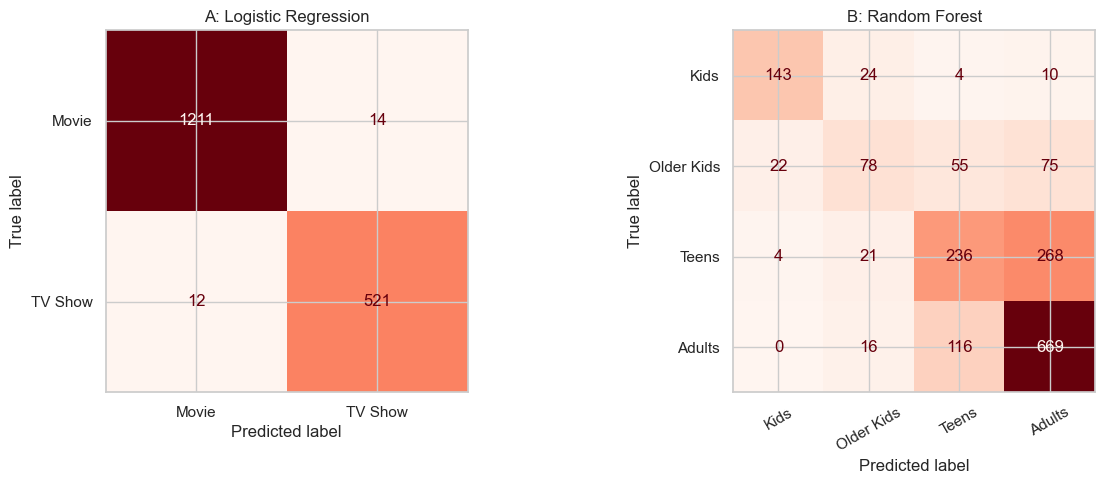

In [9]:
# confusion matrices for the best model on each problem (by CV accuracy)
bestA = cvA['cv_acc_mean'].idxmax(); bestB = cvB['cv_acc_mean'].idxmax()
print('Best A:', bestA, '| Best B:', bestB)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_estimator(modelsA[bestA], XA_te, yA_te, display_labels=['Movie', 'TV Show'], cmap='Reds', ax=ax[0], colorbar=False)
ax[0].set_title(f'A: {bestA}')
ConfusionMatrixDisplay.from_estimator(modelsB[bestB], XB_te, yB_te, labels=classes_B, cmap='Reds', ax=ax[1], colorbar=False, xticks_rotation=30)
ax[1].set_title(f'B: {bestB}')
plt.tight_layout(); plt.show()

In [10]:
print('Per-class report - Problem B,', bestB)
print(classification_report(yB_te, modelsB[bestB].predict(XB_te), labels=classes_B, zero_division=0))

Per-class report - Problem B, Random Forest
              precision    recall  f1-score   support

        Kids       0.85      0.79      0.82       181
  Older Kids       0.56      0.34      0.42       230
       Teens       0.57      0.45      0.50       529
      Adults       0.65      0.84      0.73       801

    accuracy                           0.65      1741
   macro avg       0.66      0.60      0.62      1741
weighted avg       0.64      0.65      0.63      1741



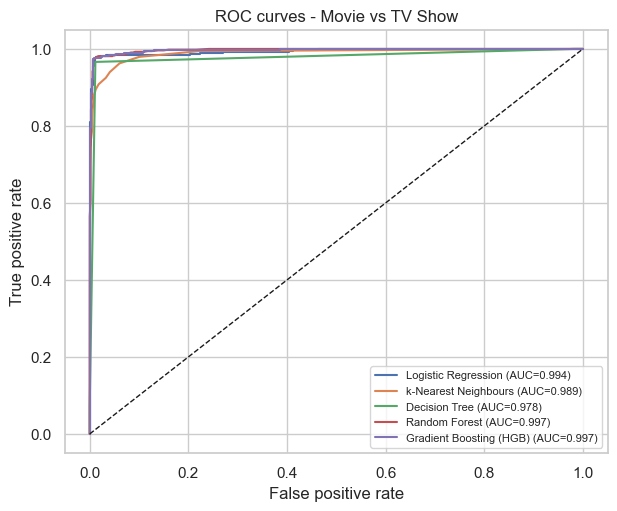

In [11]:
# ROC curves for Problem A (all probabilistic models)
plt.figure(figsize=(7, 5.5))
for name, m in modelsA.items():
    if name.startswith('Dummy'): continue
    fpr, tpr, _ = roc_curve(yA_te, m.predict_proba(XA_te)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yA_te, m.predict_proba(XA_te)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves - Movie vs TV Show')
plt.legend(fontsize=8); plt.show()

## Step 5 – Compare model accuracy

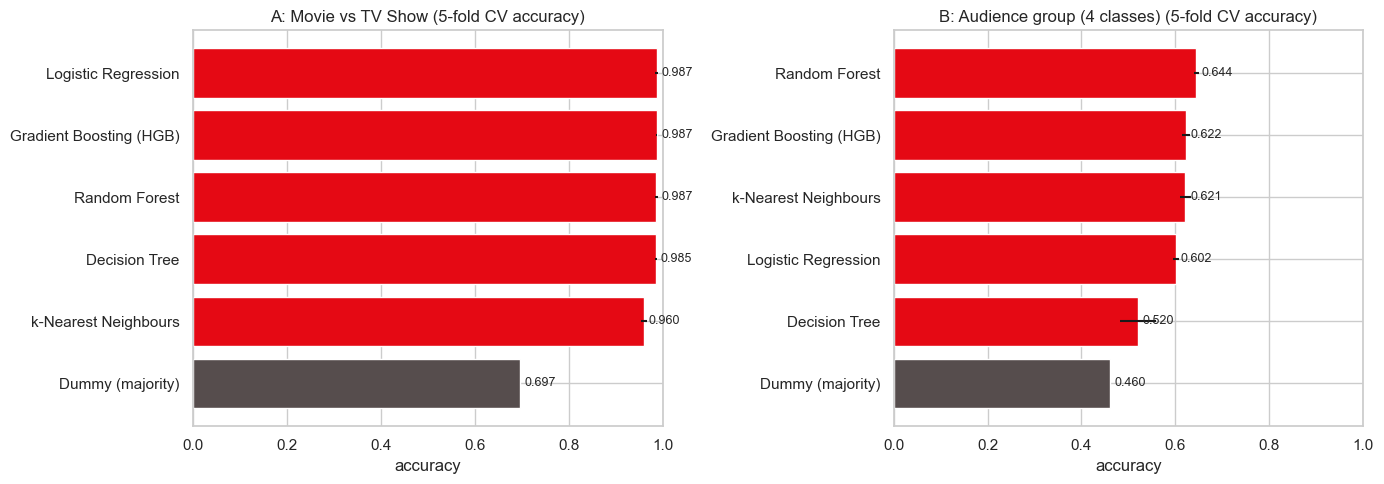

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, tbl, ttl in zip(ax, [cvA, cvB], ['A: Movie vs TV Show', 'B: Audience group (4 classes)']):
    t = tbl.sort_values('cv_acc_mean')
    a.barh(t.index, t['cv_acc_mean'], xerr=t['cv_acc_std'], color=[GREY if 'Dummy' in i else RED for i in t.index])
    a.set_xlim(0, 1); a.set_title(ttl + ' (5-fold CV accuracy)'); a.set_xlabel('accuracy')
    for i, v in enumerate(t['cv_acc_mean']): a.text(v + .01, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

In [13]:
# hyper-parameter tuning of the best tree-based model (small grid - keeps the run time short)
def tune(X, y, estimator, grid):
    gs = GridSearchCV(estimator, grid, cv=skf, scoring='f1_macro', n_jobs=-1).fit(X, y)
    return gs

gsA = tune(XA_tr, yA_tr, BalancedHGB(random_state=RANDOM_STATE),
           {'learning_rate': [.05, .1], 'max_depth': [3, 6, None], 'max_iter': [150, 300]})
gsB = tune(XB_tr, yB_tr, BalancedHGB(random_state=RANDOM_STATE),
           {'learning_rate': [.05, .1], 'max_depth': [3, 6, None], 'max_iter': [150, 300]})
print('A best params:', gsA.best_params_, '| CV macro-F1:', round(gsA.best_score_, 3))
print('B best params:', gsB.best_params_, '| CV macro-F1:', round(gsB.best_score_, 3))

for nm, gs, Xte, yte, base_m in [('A', gsA, XA_te, yA_te, modelsA['Gradient Boosting (HGB)']),
                                 ('B', gsB, XB_te, yB_te, modelsB['Gradient Boosting (HGB)'])]:
    print(f"{nm}: test accuracy default={accuracy_score(yte, base_m.predict(Xte)):.3f} -> tuned={accuracy_score(yte, gs.best_estimator_.predict(Xte)):.3f}")

A best params: {'learning_rate': 0.05, 'max_depth': None, 'max_iter': 300} | CV macro-F1: 0.984
B best params: {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 150} | CV macro-F1: 0.615
A: test accuracy default=0.985 -> tuned=0.987
B: test accuracy default=0.634 -> tuned=0.616


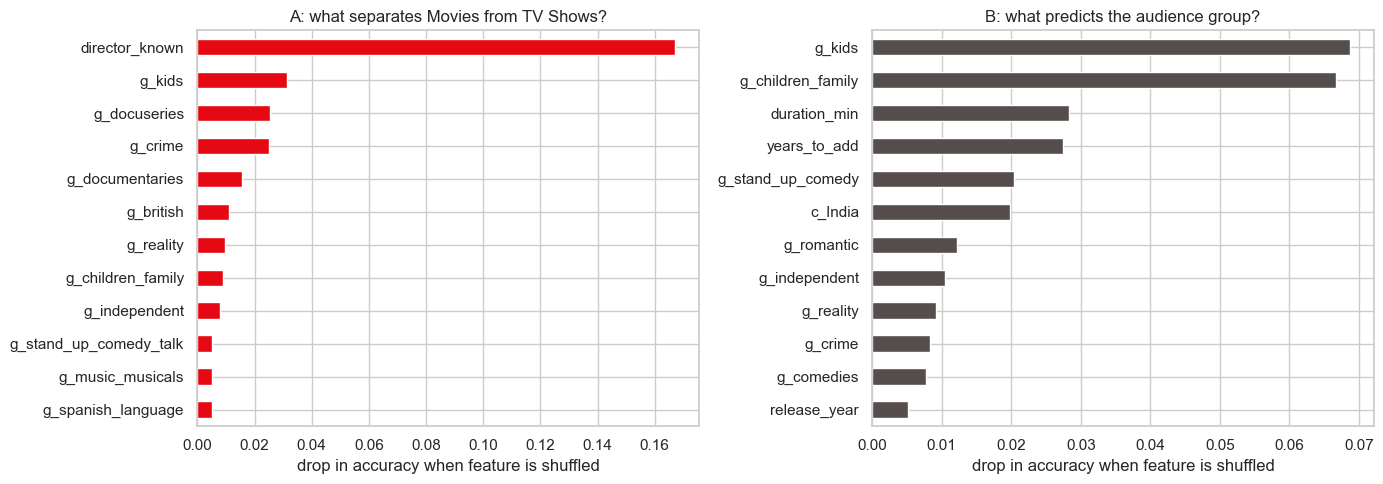

A top features: {'director_known': 0.167, 'g_kids': 0.031, 'g_docuseries': 0.025, 'g_crime': 0.025, 'g_documentaries': 0.016, 'g_british': 0.011}
B top features: {'g_kids': 0.069, 'g_children_family': 0.067, 'duration_min': 0.028, 'years_to_add': 0.027, 'g_stand_up_comedy': 0.02, 'c_India': 0.02}


In [14]:
# which features drive the predictions? permutation importance on the test set (model-agnostic, less biased than impurity importances)
def top_imp(model, Xte, yte, n=12):
    r = permutation_importance(model, Xte, yte, n_repeats=8, random_state=RANDOM_STATE, scoring='accuracy', n_jobs=-1)
    return pd.Series(r.importances_mean, index=Xte.columns).sort_values(ascending=False).head(n)

impA, impB = top_imp(gsA.best_estimator_, XA_te, yA_te), top_imp(gsB.best_estimator_, XB_te, yB_te)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
impA[::-1].plot(kind='barh', ax=ax[0], color=RED); ax[0].set_title('A: what separates Movies from TV Shows?')
impB[::-1].plot(kind='barh', ax=ax[1], color=GREY); ax[1].set_title('B: what predicts the audience group?')
for a in ax: a.set_xlabel('drop in accuracy when feature is shuffled')
plt.tight_layout(); plt.show()
print('A top features:', impA.round(3).head(6).to_dict())
print('B top features:', impB.round(3).head(6).to_dict())

In [15]:
# final summary table: baseline vs tuned vs best, on the held-out test set
final = pd.DataFrame({
    'A: Movie vs TV': {'majority baseline': resA.loc['Dummy (majority)', 'accuracy'],
                       'best default model': resA['accuracy'].drop('Dummy (majority)').max(),
                       'tuned HGB': accuracy_score(yA_te, gsA.best_estimator_.predict(XA_te))},
    'B: Audience (4 classes)': {'majority baseline': resB.loc['Dummy (majority)', 'accuracy'],
                                'best default model': resB['accuracy'].drop('Dummy (majority)').max(),
                                'tuned HGB': accuracy_score(yB_te, gsB.best_estimator_.predict(XB_te))}}).round(3)
final

,A: Movie vs TV,B: Audience (4 classes)
majority baseline,0.697,0.460
best default model,0.986,0.647
tuned HGB,0.987,0.616


## Summary of results

**Test-set accuracy (held-out 20%)**

| Model | A: Movie vs TV Show | B: Audience (4 classes) |
|---|---|---|
| Dummy (majority) baseline | 69.7% | 46.0% |
| Logistic Regression | 98.5% | 60.2% |
| k-Nearest Neighbours | 95.8% | 62.6% |
| Decision Tree | 98.2% | 59.3% |
| **Random Forest** | **98.6%** | **64.7%** |
| Gradient Boosting (HGB) | 98.5% | 63.4% |
| Gradient Boosting, tuned | 98.7% | 61.6% |

5-fold cross-validation agrees with the single split (A: ~98.7% for Logistic Regression / Random Forest / Gradient Boosting; B: Random Forest best at ~64.4%).

**Problem A – Movie vs TV Show**
- Every model except k-NN reaches ~98–99% accuracy (ROC-AUC ≈ 0.997), far above the 69.7% majority baseline, **without** using duration.
- The strongest signal is simply **whether a director is listed** (TV shows rarely have one), followed by TV-specific genre labels such as *Kids*, *Docuseries* and *Crime*.
- Because the genre taxonomy itself differs between movies and series, this is an "easy" problem; the model is learning catalogue labelling conventions as much as anything about the content.

**Problem B – Audience group (Kids / Older Kids / Teens / Adults)**
- The best model (Random Forest) is **~19 points above the baseline** (64.7% vs 46.0%; macro-F1 ≈ 0.62; ROC-AUC ≈ 0.84), a solid result for a hard 4-class problem using only metadata.
- Per-class (Random Forest): **Kids is easy** (F1 0.82), **Adults is good** (F1 0.73, recall 0.84), while **Older Kids (F1 0.42) and Teens (F1 0.50) are the hard middle groups** - they overlap heavily in genre, country and format.
- The most useful features are the Kids / Children & Family genre flags, movie duration, time between release and Netflix addition, stand-up comedy and country (India).
- **Tuning did not help here:** the tuned boosting model scored 61.6% on the test set vs 63.4% for the default, because the grid optimised cross-validated macro-F1 and the differences are within noise. The sensible conclusion is that more tuning won't fix a feature problem.

**Recommendation:** use **Random Forest** (best, stable on both problems; Logistic Regression is an equally good, simpler choice for Problem A). To improve Problem B, add text features (plot descriptions / cast) - metadata alone cannot reliably separate Teens from Older Kids.

**Caveats**
- Leakage was checked explicitly: `duration` gives 100% on Problem A and `rating` is the answer to Problem B, so both are excluded.
- "Not Rated" titles (82) were removed from Problem B.
- Results come from one random split + 5-fold CV on a 2021 snapshot; class definitions come from a hand-made rating-to-audience mapping (Task 1), so Problem B inherits that choice.
